# Laboratorio 3
## Deep Learning: Reconocimiento de Lenguaje de Señas ASL

**CC3084 - Data Science · Semestre II 2026**

Este notebook funciona como informe ejecutable. Todos los conteos, tiempos, métricas,
gráficos y conclusiones cuantitativas que aparecen abajo provienen de los artefactos
producidos por una ejecución real de `src.run_lab`. No se utilizan arquitecturas
preentrenadas ni LSTM: la metodología principal sigue el ejemplo CNN de gatos y perros.

> **Versión correspondiente al commit 2 de 3 — Modelos y experimentos**
>
> **Alcance:** Todo el trabajo del commit 1 más CNN1, CNN2, dropout, learning rate, image augmentation, fully connected y SVM.
> **Mensaje de commit sugerido:** `feat: add ASL model experiments and baselines`
>
> Esta es una versión progresiva del notebook. El notebook final original permanece en `notebooks/Lab03_ASL.ipynb`.


## 1. Introducción

SignBridge plantea un primer prototipo para reconocer letras ASL a partir de fotografías
de manos. Este laboratorio resuelve clasificación multiclase de imágenes estáticas; no
pretende ser todavía un traductor ASL en tiempo real.

## 2. Objetivos

- Explorar y verificar el dataset ASL Alphabet.
- Crear una división estratificada 60/20/20 sin imágenes compartidas.
- Comparar CNN de complejidad progresiva, Dropout y augmentation.
- Contrastar contra una red fully-connected y SVM.
- Reservar test hasta congelar la selección basada en validation.
- Analizar errores, accesibilidad, sesgo y límites del prototipo.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage, Markdown

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.run_lab import run_complete_lab
from src.config import *
from src.models import build_cnn1, build_cnn2, build_fully_connected
from src.preprocessing import build_generators
from src.evaluation import predecir_imagen
from tensorflow import keras

# Si faltara cualquier artefacto, esta llamada ejecutaría el pipeline completo.
# En una reproducción ya terminada reutiliza modelos y métricas verificadas.
run_summary = run_complete_lab(force=False)
print("Pipeline completo y verificado.")

Pipeline completo y verificado.


## 3. Dataset

### Preguntas

¿Cuántas imágenes y clases existen? ¿El dataset está balanceado? ¿Todas las imágenes
tienen resolución, formato y canales consistentes? ¿Hay archivos inválidos?

La auditoría abrió y verificó **87,000 archivos**. Encontró
**87,000 imágenes válidas**, **0 inválidas**
y **29 clases**. Los conteos van de
3,000 a 3,000; la diferencia real es
0 imágenes. Por tanto, el balance no se asume: queda
cuantificado por esa diferencia y por la tabla siguiente.

,class,image_count,percentage
0,A,3000,3.4483%
1,B,3000,3.4483%
2,C,3000,3.4483%
3,D,3000,3.4483%
4,E,3000,3.4483%
5,F,3000,3.4483%
6,G,3000,3.4483%
7,H,3000,3.4483%
8,I,3000,3.4483%
9,J,3000,3.4483%


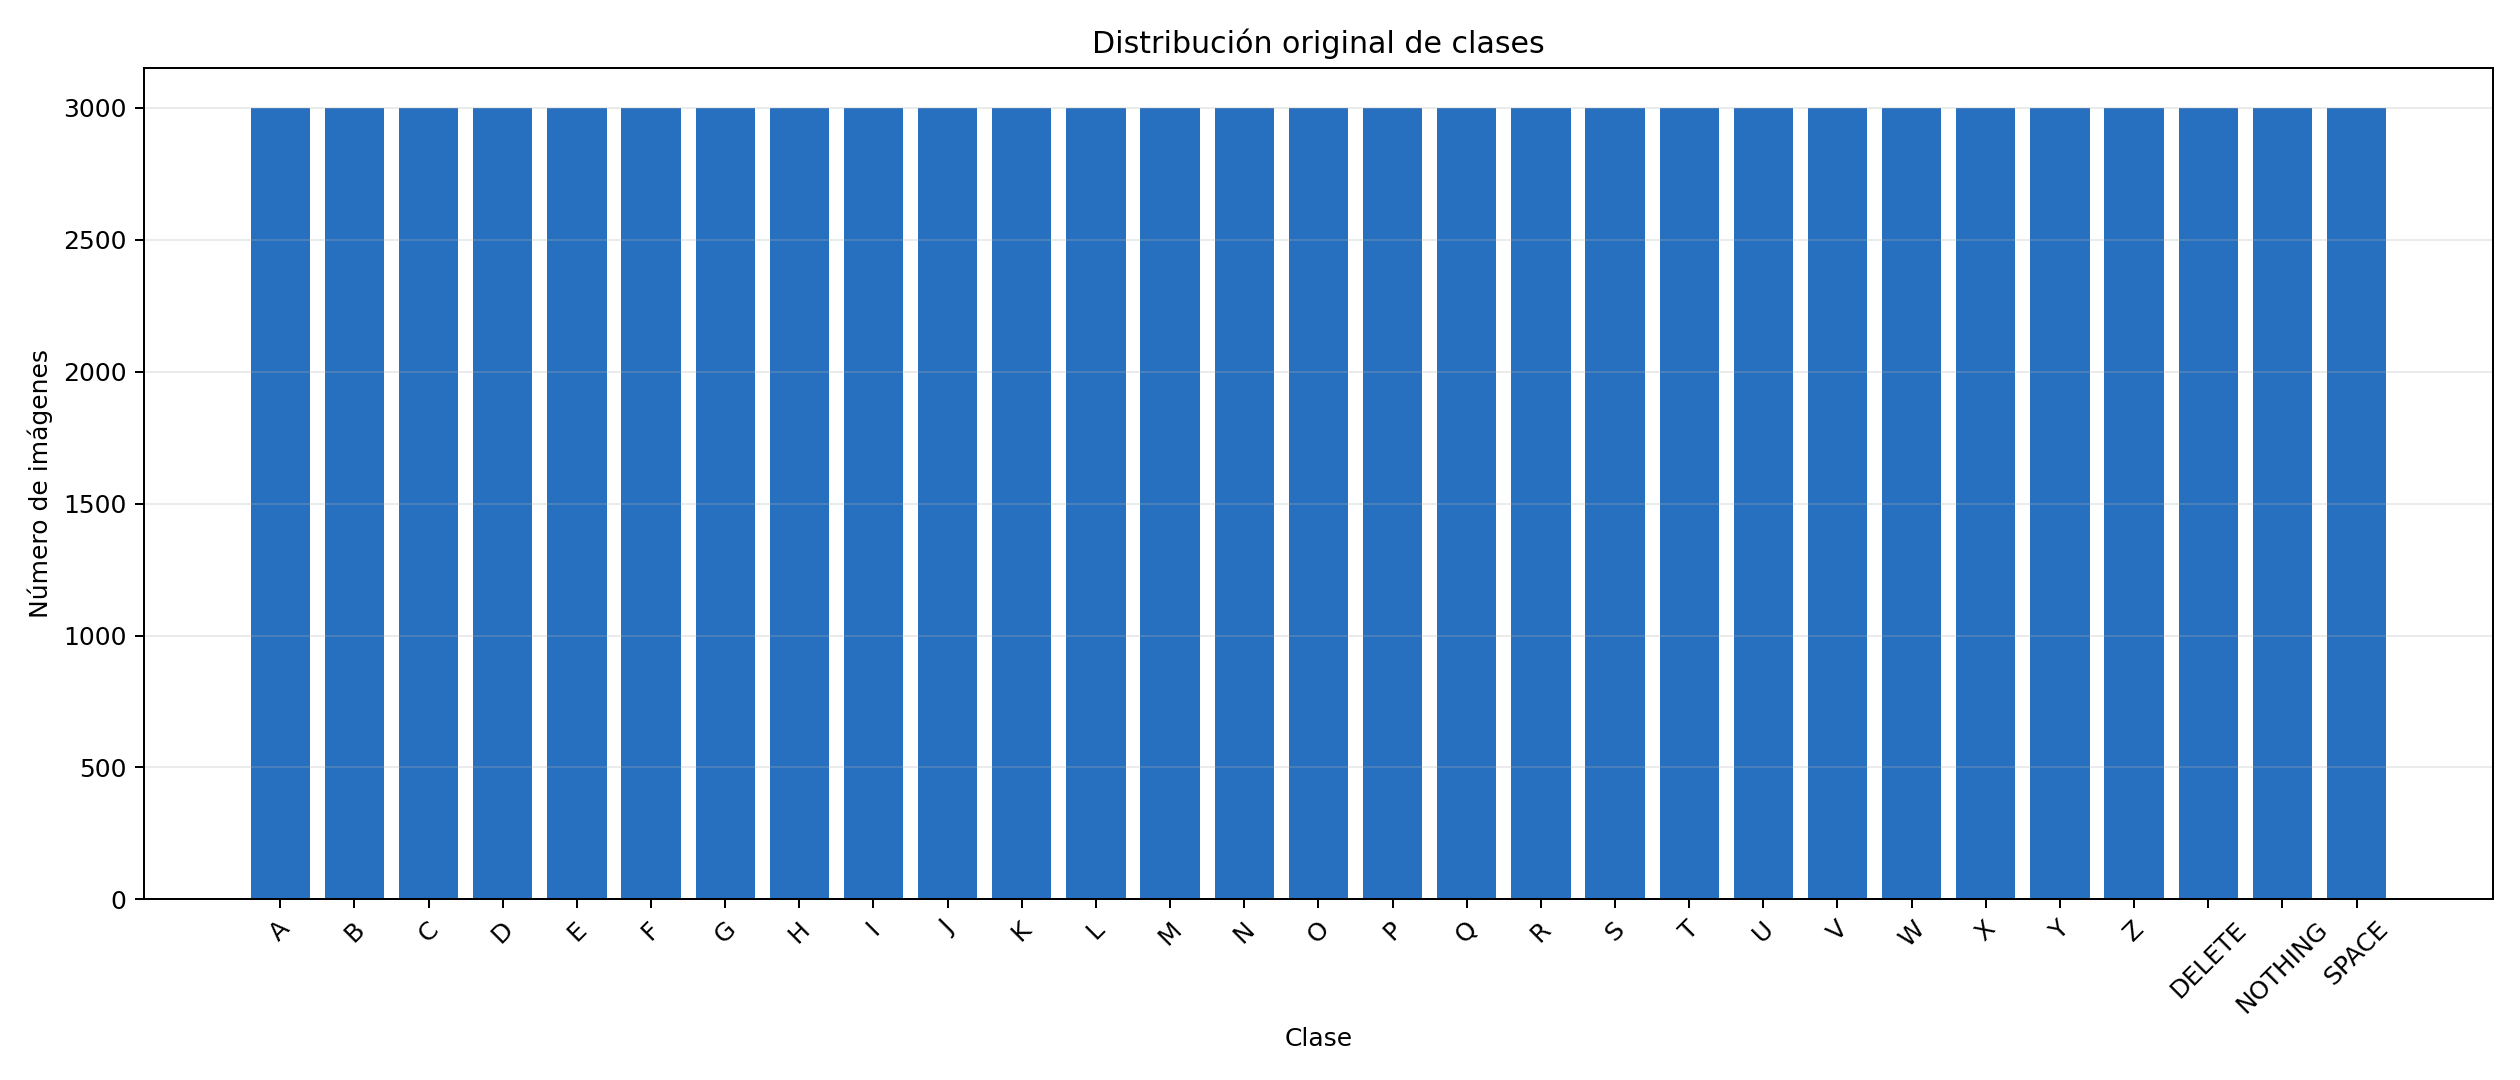

In [2]:
distribution = pd.read_csv("outputs/metrics/class_distribution.csv")
display(distribution.style.format({"percentage": "{:.4f}%"}))
display(IPImage(filename="outputs/figures/class_distribution.png"))

La resolución dominante auditada es **200×200**,
el formato observado es {'.jpg': 87000} y los modos de color son
{'RGB': 87000}. La diferencia de 0 entre la clase
con mayor y menor cantidad confirma un conjunto perfectamente balanceado en imágenes válidas
solo si esa diferencia es cero; ese fue el resultado observado aquí.

## 4. Análisis exploratorio

### 4.1 Ejemplos visuales y variabilidad

¿Cómo cambian posición, iluminación, escala, orientación, ubicación de la mano y dedos
dentro y entre clases? Las imágenes siguientes son muestras reales elegidas con semilla 123.

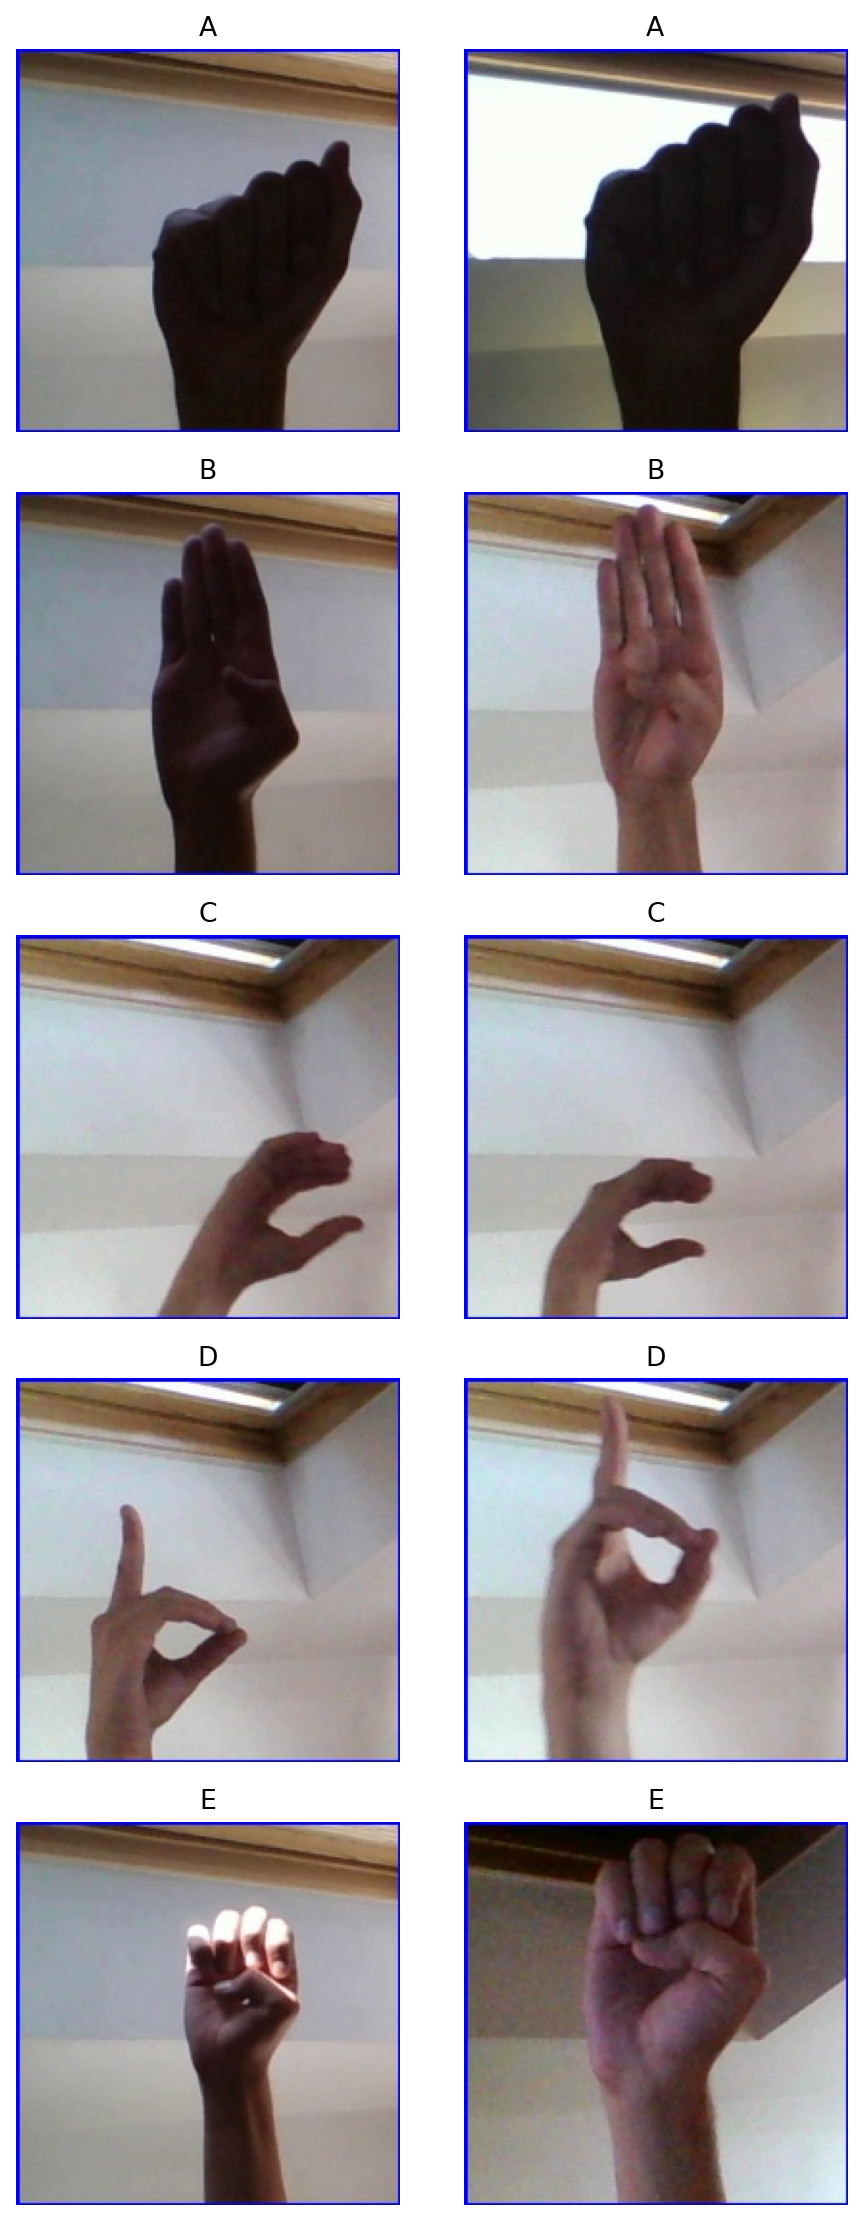

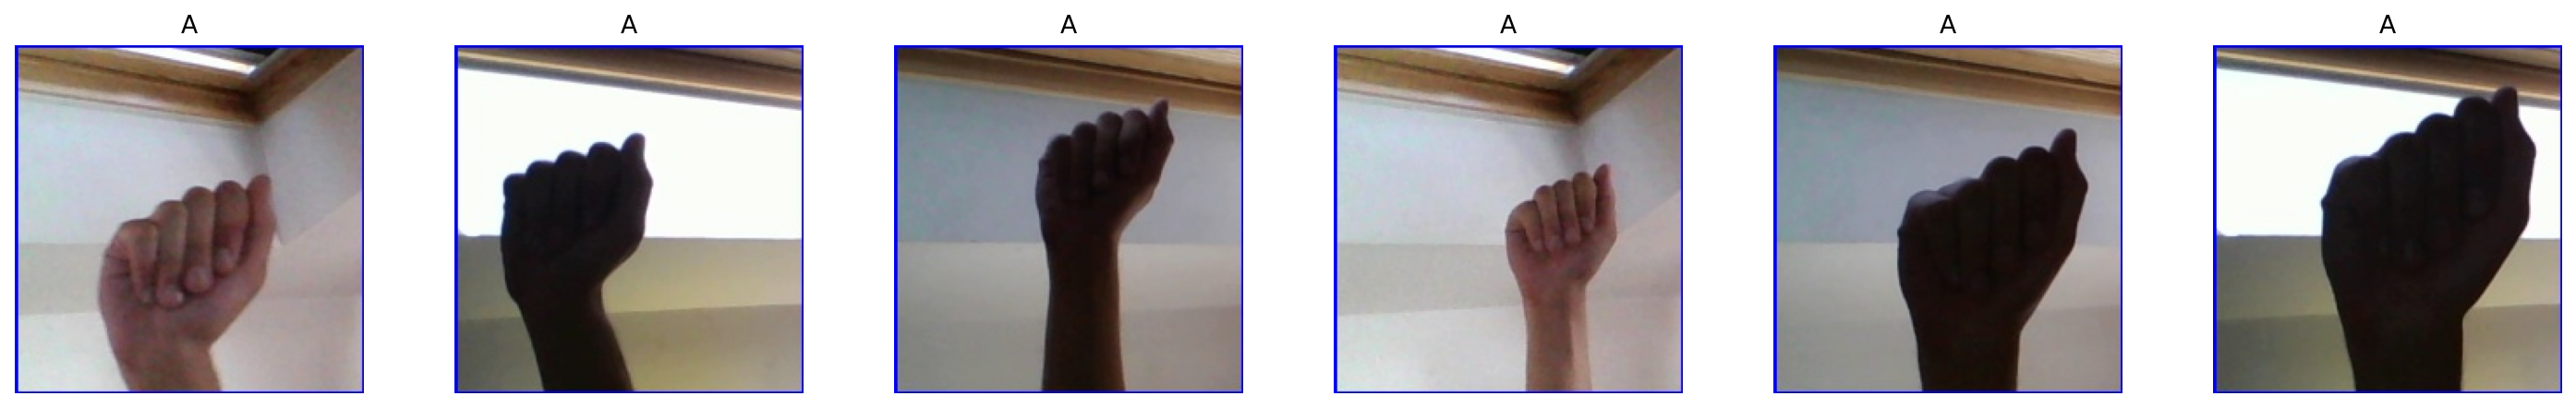

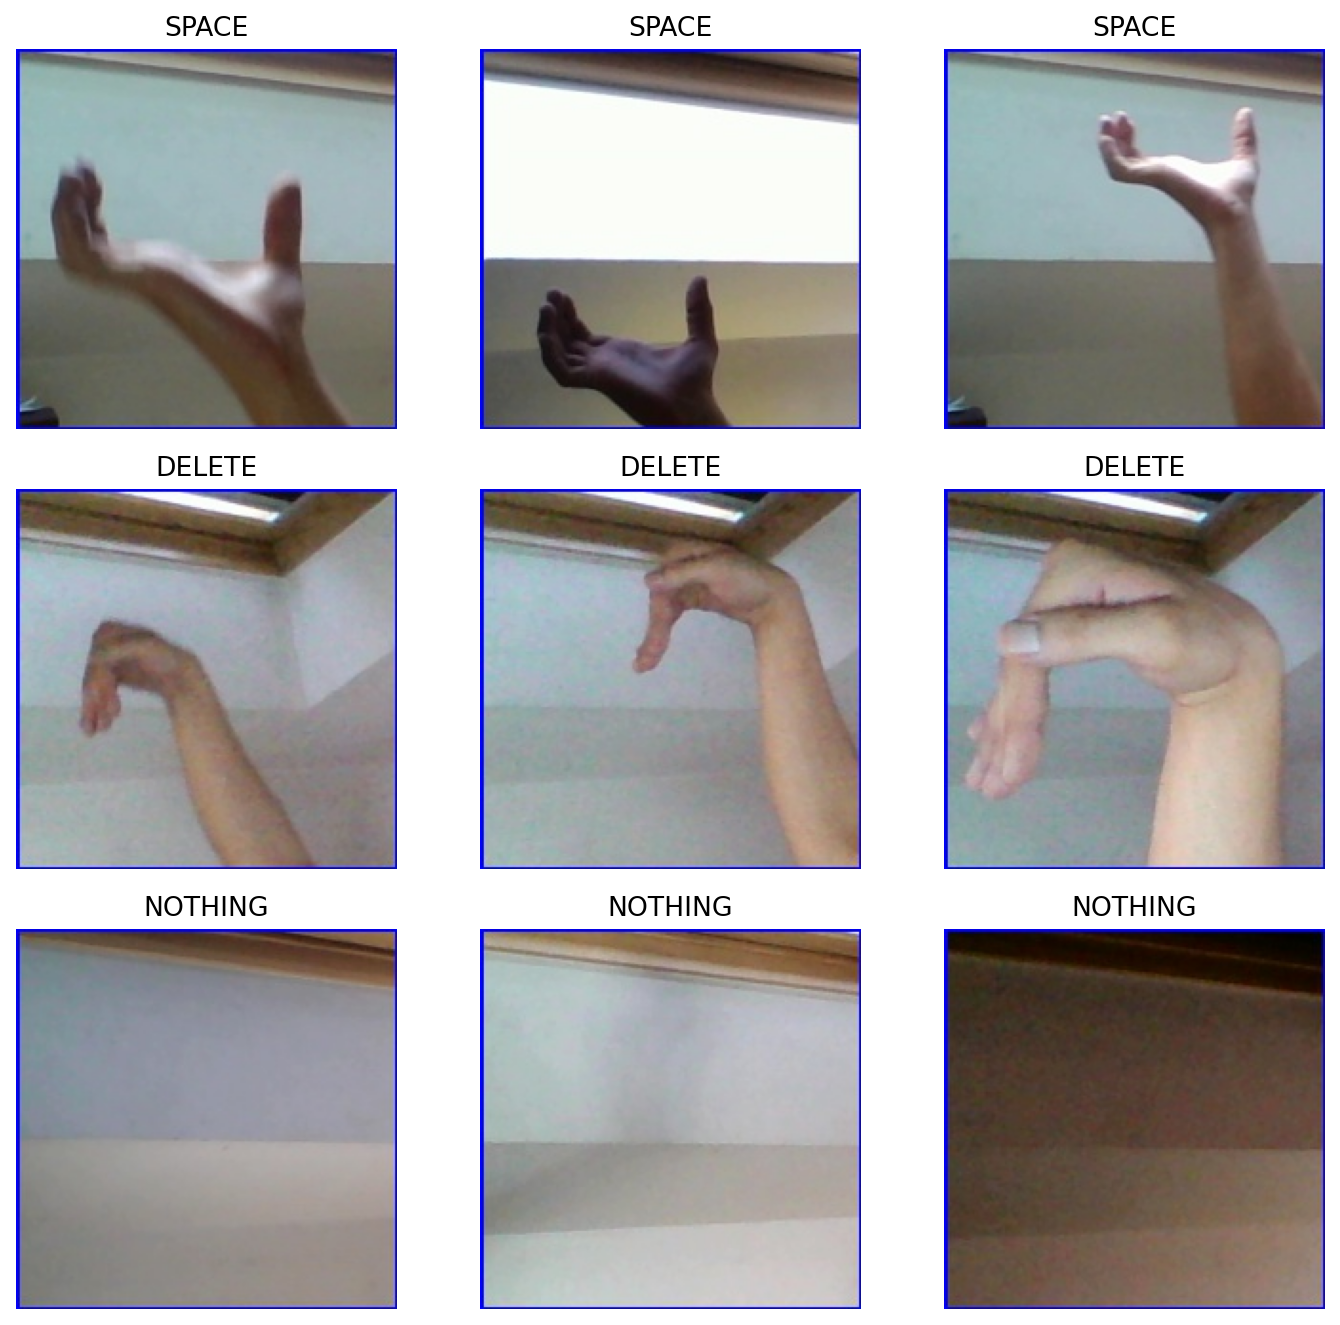

In [3]:
for path in [
    "outputs/figures/five_letters.png",
    "outputs/figures/within_class_A.png",
    "outputs/figures/special_classes.png",
]:
    display(IPImage(filename=path))

Las fotografías conservan fondo e iluminación relativamente uniformes, pero dentro de una
misma clase se aprecian desplazamientos, ligeros cambios de escala/orientación y variaciones
en la flexión de los dedos. Esa variabilidad justifica aprender características y aplicar
transformaciones moderadas, sin asumir que cualquier transformación conserva la etiqueta.

### 4.2 Clases visualmente similares

Antes de entrenar se planteó la hipótesis de que M/N/S y U/V/R podrían ser difíciles por
las diferencias sutiles en la colocación o cruce de dedos. Esto es una hipótesis visual,
no una afirmación sobre las confusiones reales.

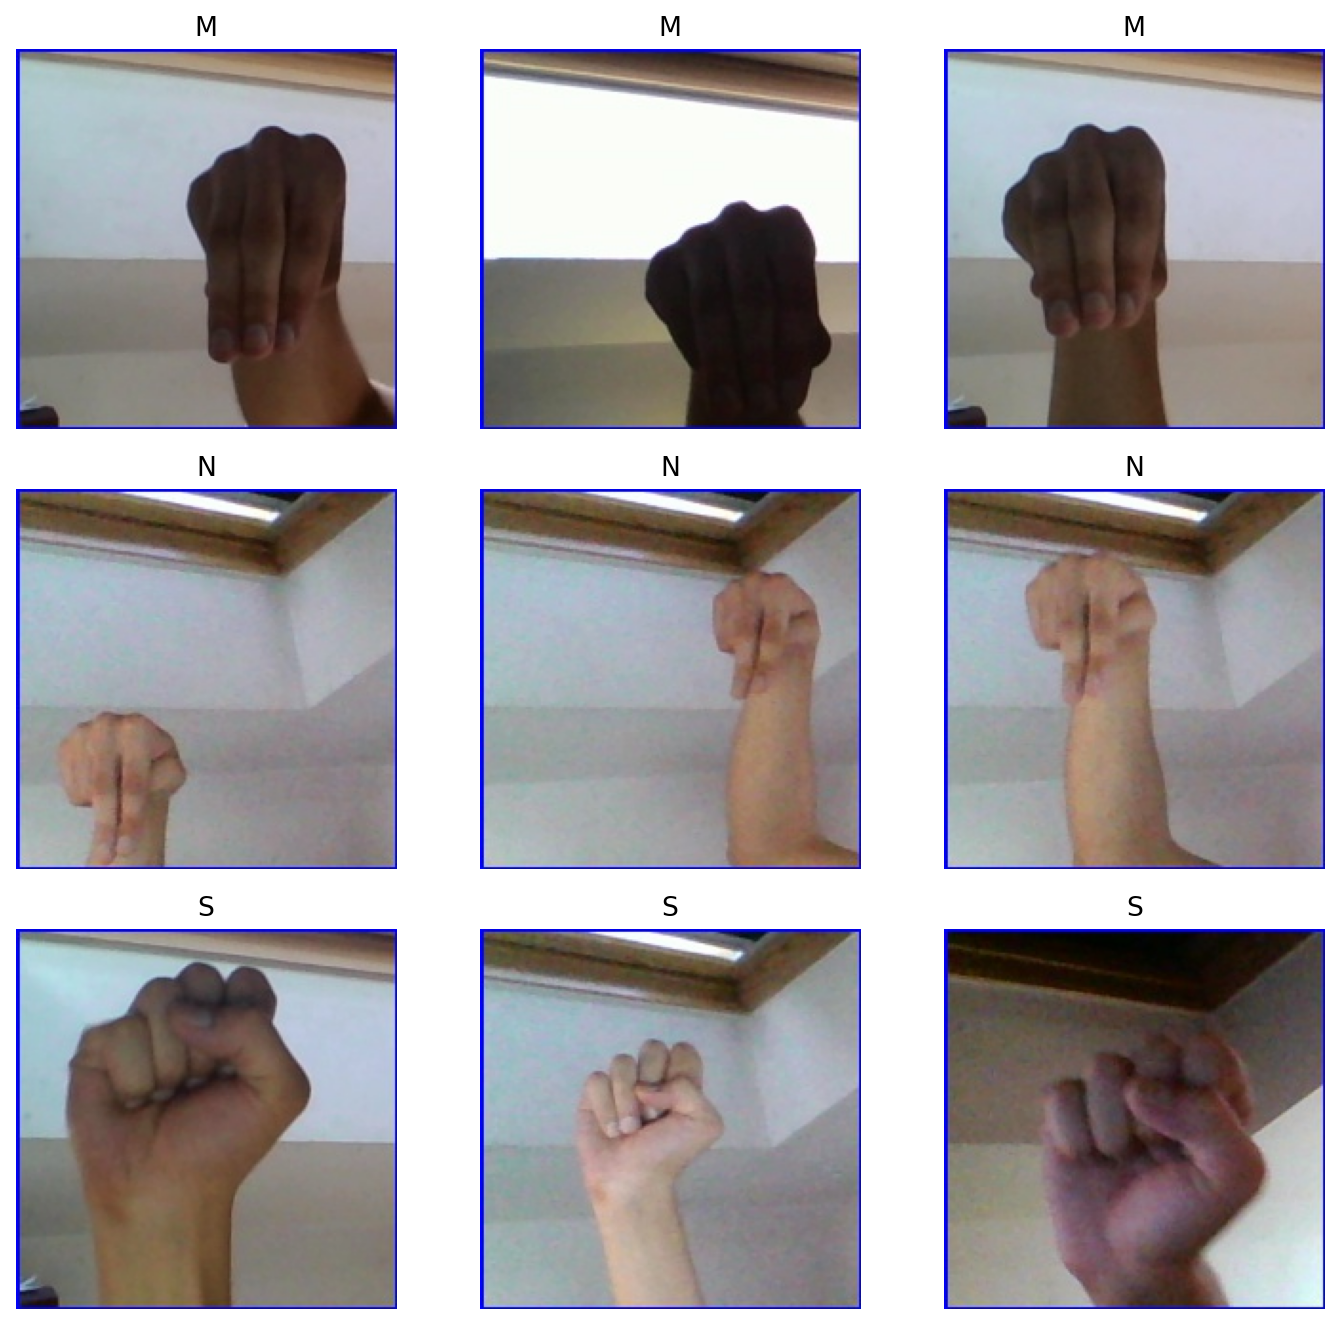

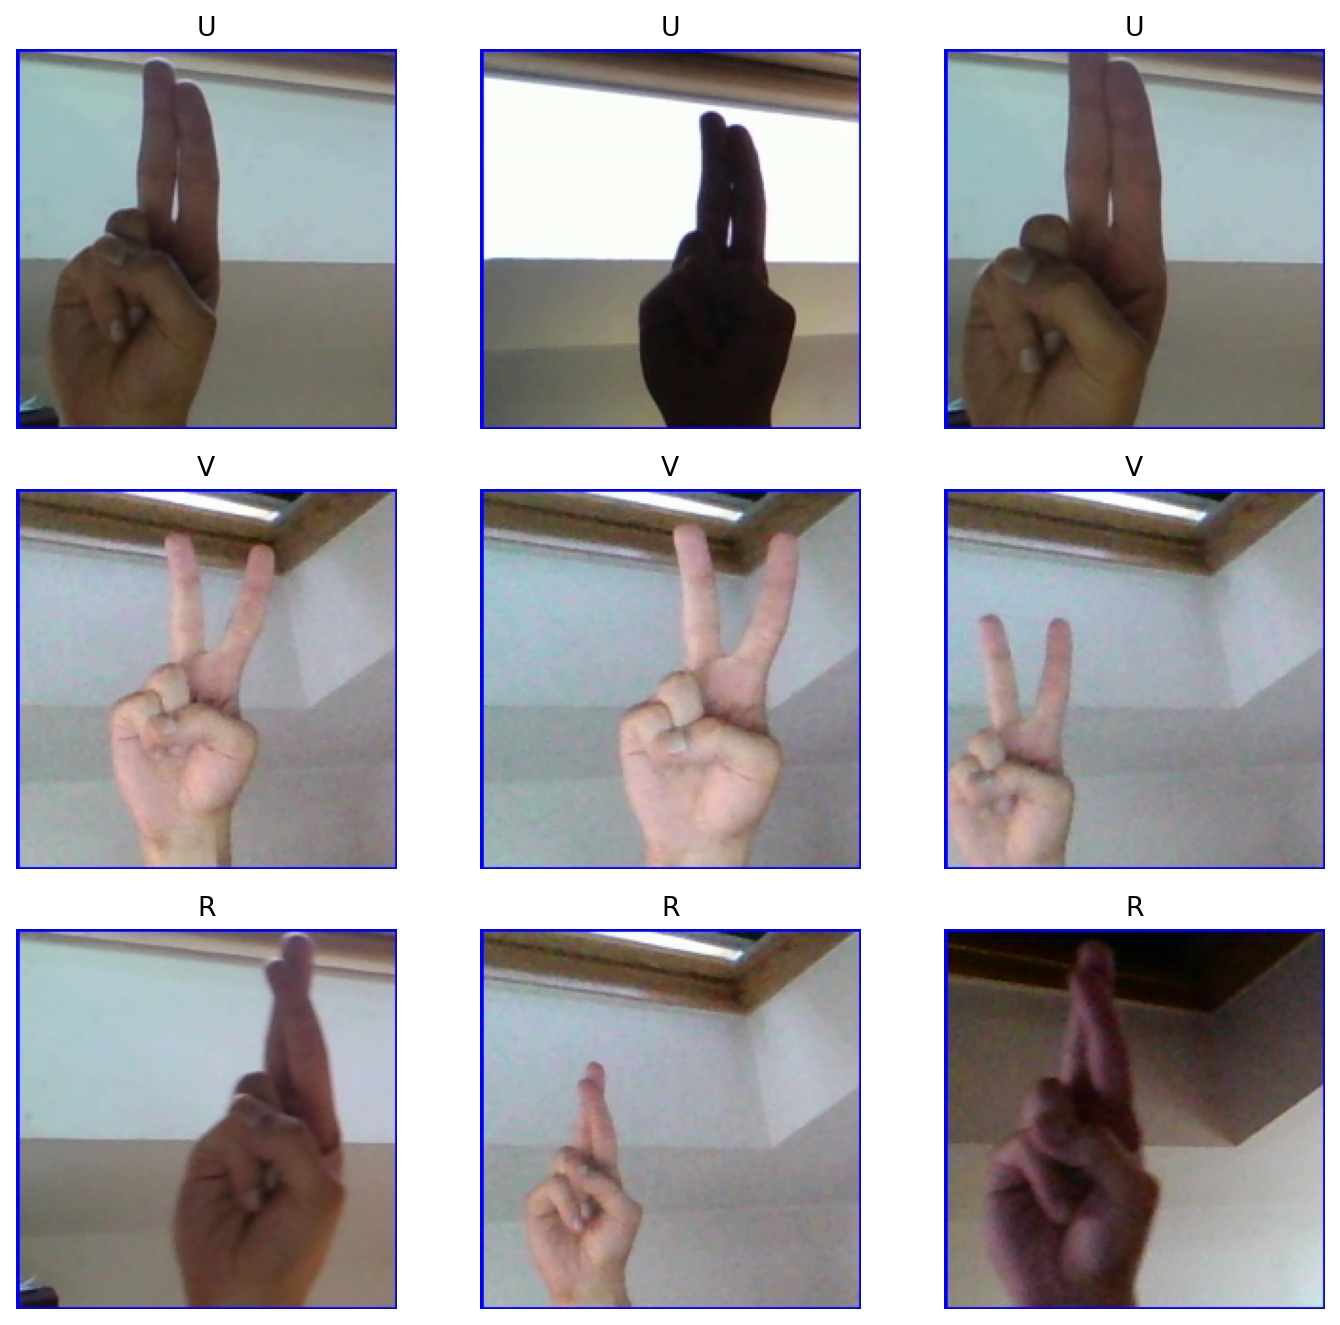

In [4]:
display(IPImage(filename="outputs/figures/similar_MNS.png"))
display(IPImage(filename="outputs/figures/similar_UVR.png"))

## 5. Submuestreo

Se seleccionaron aleatoriamente **600 imágenes válidas por clase**,
sin reemplazo y con `RANDOM_SEED=123`: **17,400 imágenes** en total.
Se escogió 600 porque está dentro del rango 500-800 indicado por el laboratorio y permite
ejecutar diez experimentos en una computadora de 16 GB sin usar simplemente los primeros archivos.

## 6. División Train / Validation / Test

La división estratificada fue 60/20/20: **10,440 train**,
**3,480 validation** y **3,480 test**.
Las 29 clases están presentes con 360/120/120 imágenes respectivamente.

In [5]:
split_table = pd.read_csv("outputs/metrics/split_by_class.csv")
leakage = json.loads(Path("outputs/metrics/leakage_check.json").read_text())
display(split_table)
print("Intersecciones:", leakage["intersections"])
print("Imágenes fuente únicas:", leakage["unique_source_images"])
assert leakage["verified"] and all(v == 0 for v in leakage["intersections"].values())

,display_class,train,validation,test
0,A,360,120,120
1,B,360,120,120
2,C,360,120,120
3,D,360,120,120
4,DELETE,360,120,120
5,E,360,120,120
6,F,360,120,120
7,G,360,120,120
8,H,360,120,120
9,I,360,120,120


Intersecciones: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}
Imágenes fuente únicas: 17400


La intersección train-validation, train-test y validation-test es cero. TRAIN ajusta pesos;
VALIDATION decide arquitectura, dropout, augmentation y kernel; TEST no se consultó hasta
guardar `selection_before_test.json`. Aunque no hay duplicados exactos, las fotografías del
dataset provienen de secuencias visualmente homogéneas, una limitación que puede volver el test
interno más optimista que fotos de usuarios nuevos.

## 7. Preprocesamiento

Las imágenes se mantienen RGB, se redimensionan de 200×200×3 a 64×64×3 y se normalizan
de [0,255] a [0,1] con `rescale=1.0/255.0`. El resize reduce memoria y tiempo, conservando
la forma global de la mano recomendada para este laboratorio.

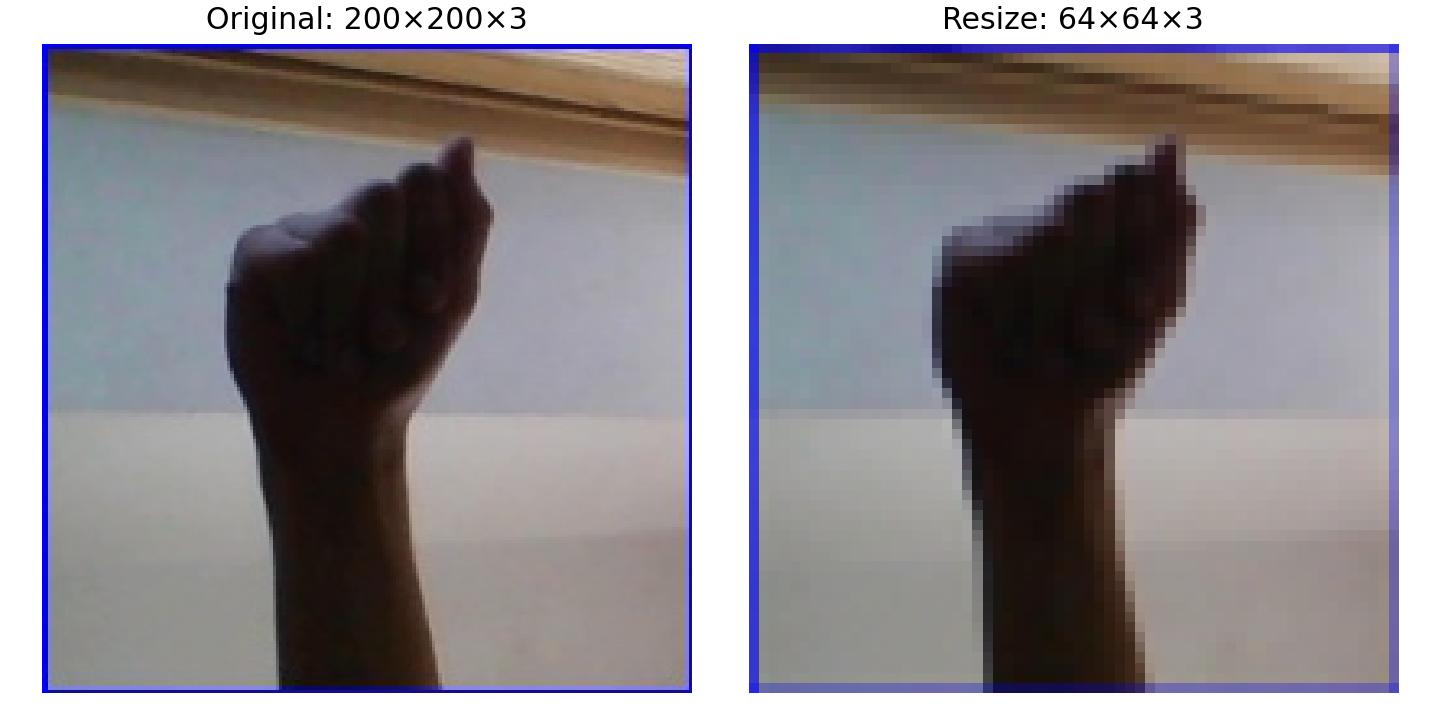

Found 10440 images belonging to 29 classes.


Found 3480 images belonging to 29 classes.


Found 3480 images belonging to 29 classes.


class_mode='categorical'; clases: 29
Validation y test: solo rescale, sin augmentation.


In [6]:
display(IPImage(filename="outputs/figures/resize_comparison.png"))
train_it, validation_it, test_it = build_generators(augmentation=False)
print("class_mode='categorical'; clases:", len(train_it.class_indices))
print("Validation y test: solo rescale, sin augmentation.")

La salida binaria del ejemplo de gatos/perros se adapta a 29 neuronas softmax,
`categorical_crossentropy` y `class_mode='categorical'`. Esto produce una distribución
de probabilidad mutuamente excluyente sobre todas las clases.

## 8. Modelo 1 - CNN básica

Model: "cnn_modelo_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,199,069 (16.02 MB)

 Trainable params: 4,199,069 (16.02 MB)

 Non-trainable params: 0 (0.00 B)

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
0,CNN1,CNN1,Conv2D(32)-MaxPool-Flatten-Dense(128)-Softmax(29),0.01,0.0,64.0,10.0,10.0,10.0,False,...,1.273882,1.400608,150.221042,4199069.0,0.479885,1.396537,0.512346,0.479885,0.46043,Test no consultado durante selección; resultad...


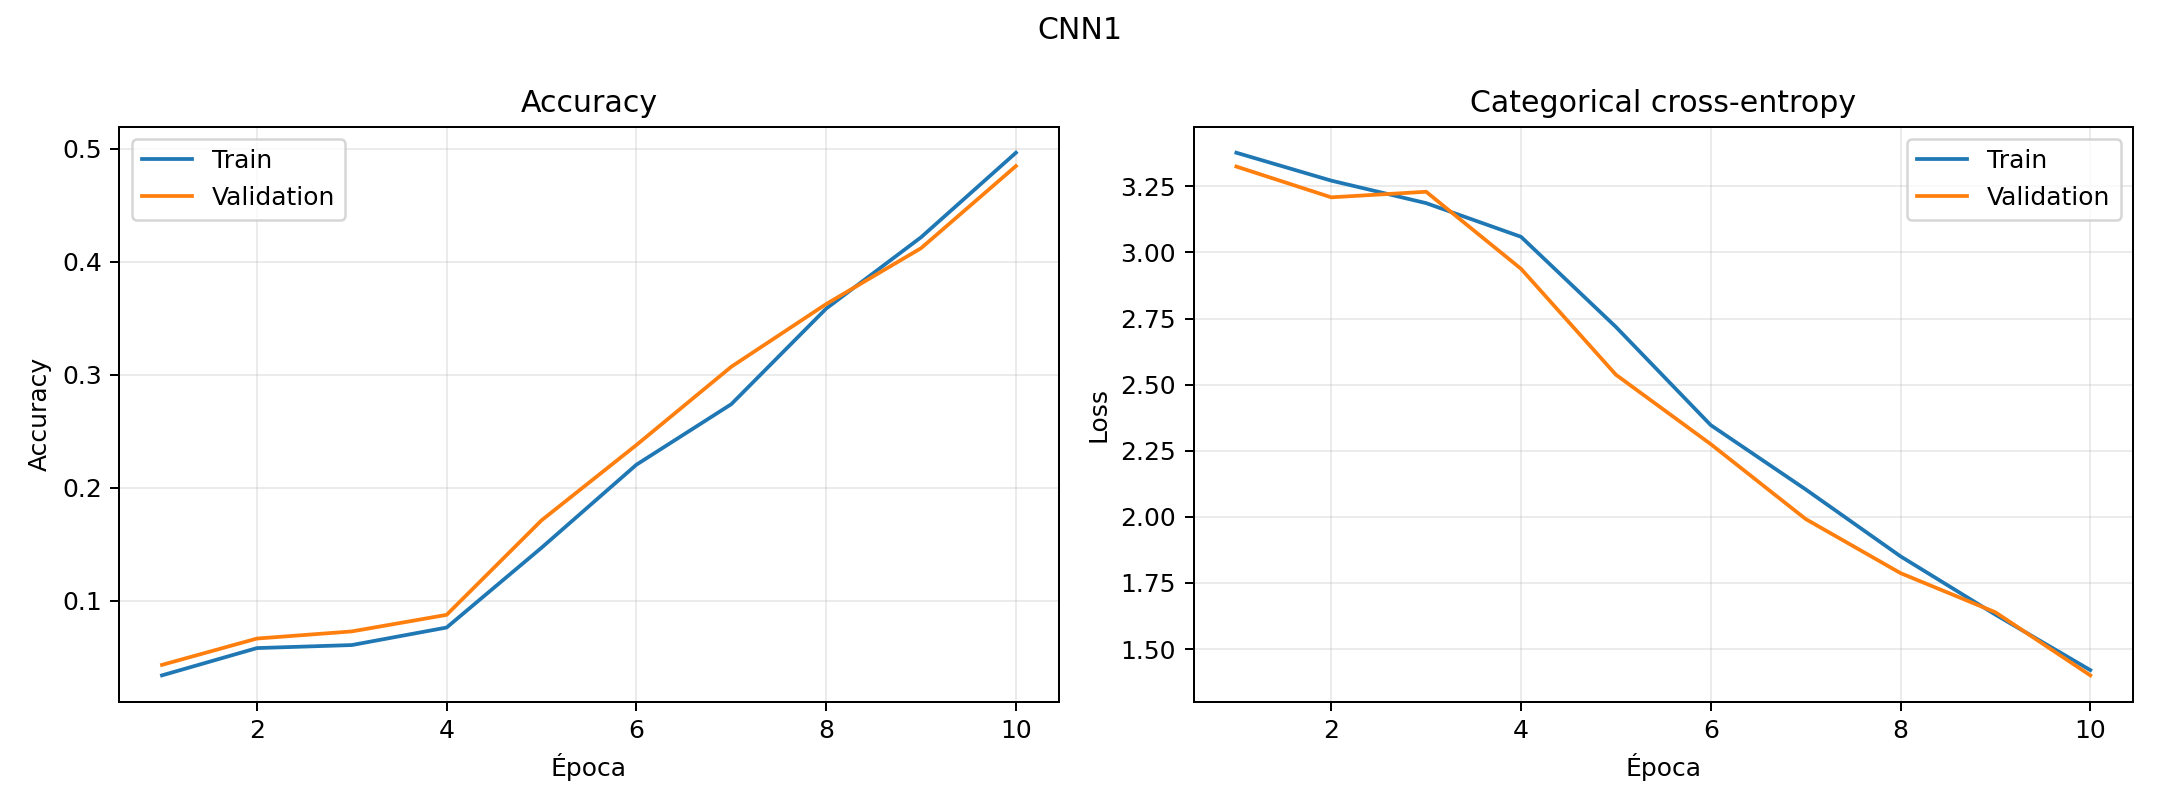

In [7]:
modelo1 = build_cnn1(learning_rate=0.01)
modelo1.summary()
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id == 'CNN1'"))
display(IPImage(filename="outputs/figures/history_cnn1.png"))

La ejecución real alcanzó 53.17% en train y 48.45% en validation (brecha +4.72 puntos porcentuales), con loss de validación 1.4006. Se entrenaron 10 épocas en 150.2 s. Esto muestra una brecha pequeña entre entrenamiento y validación.

## 9. Modelo 2 - CNN con mayor profundidad

El cambio controlado es agregar Conv2D(64)+MaxPooling2D, manteniendo Dense(128), SGD
con learning rate 0.01, momentum 0.9 y diez épocas.

Model: "cnn_modelo_2_dropout_0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,120,413 (8.09 MB)

 Trainable params: 2,120,413 (8.09 MB)

 Non-trainable params: 0 (0.00 B)

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
1,CNN2,CNN2,Conv2D(32)-MaxPool-Conv2D(64)-MaxPool-Flatten-...,0.01,0.0,64.0,10.0,10.0,10.0,False,...,0.257468,0.498967,191.019397,2120413.0,0.849138,0.475913,0.869154,0.849138,0.848526,Test no consultado durante selección; resultad...


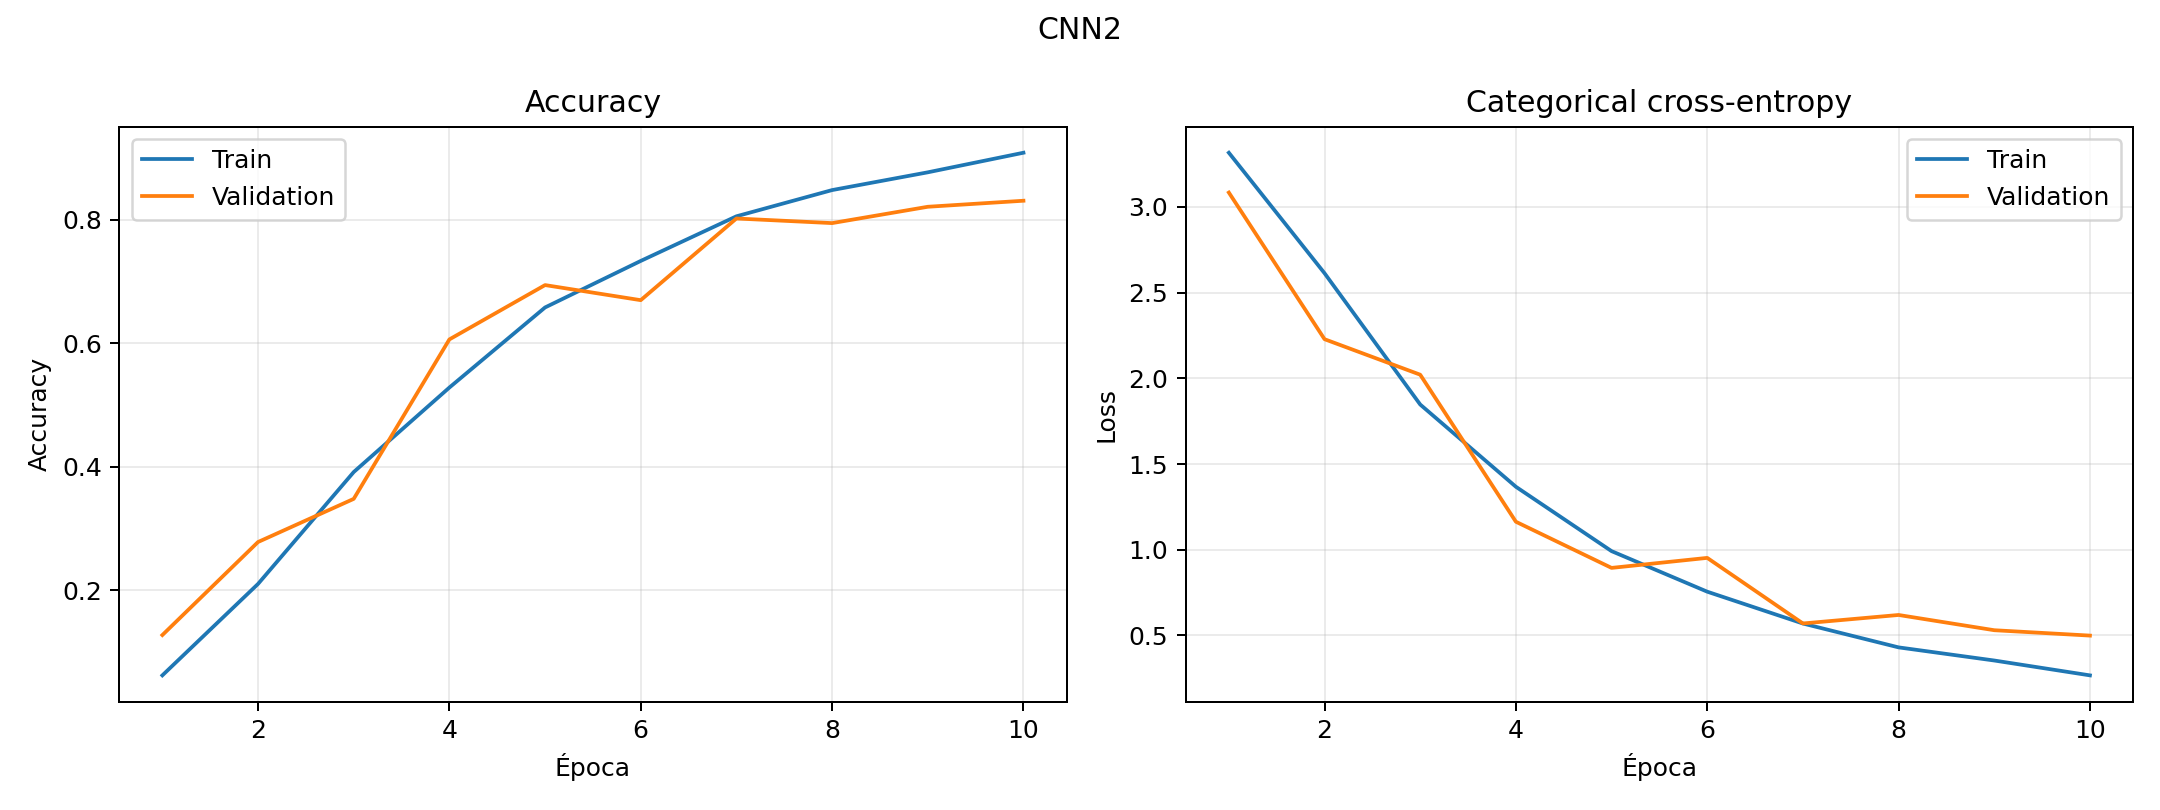

In [8]:
modelo2 = build_cnn2(learning_rate=0.01, dropout=0.0)
modelo2.summary()
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id == 'CNN2'"))
display(IPImage(filename="outputs/figures/history_cnn2.png"))

La ejecución real alcanzó 91.35% en train y 83.07% en validation (brecha +8.28 puntos porcentuales), con loss de validación 0.4990. Se entrenaron 10 épocas en 191.0 s. Esto muestra una brecha apreciable compatible con sobreajuste. El cambio de validation accuracy contra Modelo 1 fue +34.63 puntos porcentuales.

## 10. Modelo 3 - Dropout

Se comparan dos configuraciones controladas sobre la CNN de dos convoluciones. Ambas usan
SGD con learning rate 0.001; solo cambia Dropout de 0.1 a 0.2. Los entrenamientos largos
usan EarlyStopping sobre `val_loss`, patience 3 y `restore_best_weights=True`.

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
2,CNN3_D01,CNN3_D01,CNN2 + Dropout(0.1) después de cada MaxPool,0.001,0.1,64.0,15.0,15.0,15.0,False,...,2.071205,2.127171,269.546158,2120413.0,0.336494,2.136914,0.424632,0.336494,0.338425,Test no consultado durante selección; resultad...
3,CNN3_D02,CNN3_D02,CNN2 + Dropout(0.2) después de cada MaxPool,0.001,0.2,64.0,15.0,15.0,15.0,False,...,2.304457,2.320575,283.872966,2120413.0,0.280172,2.348991,0.349191,0.280172,0.268083,Test no consultado durante selección; resultad...


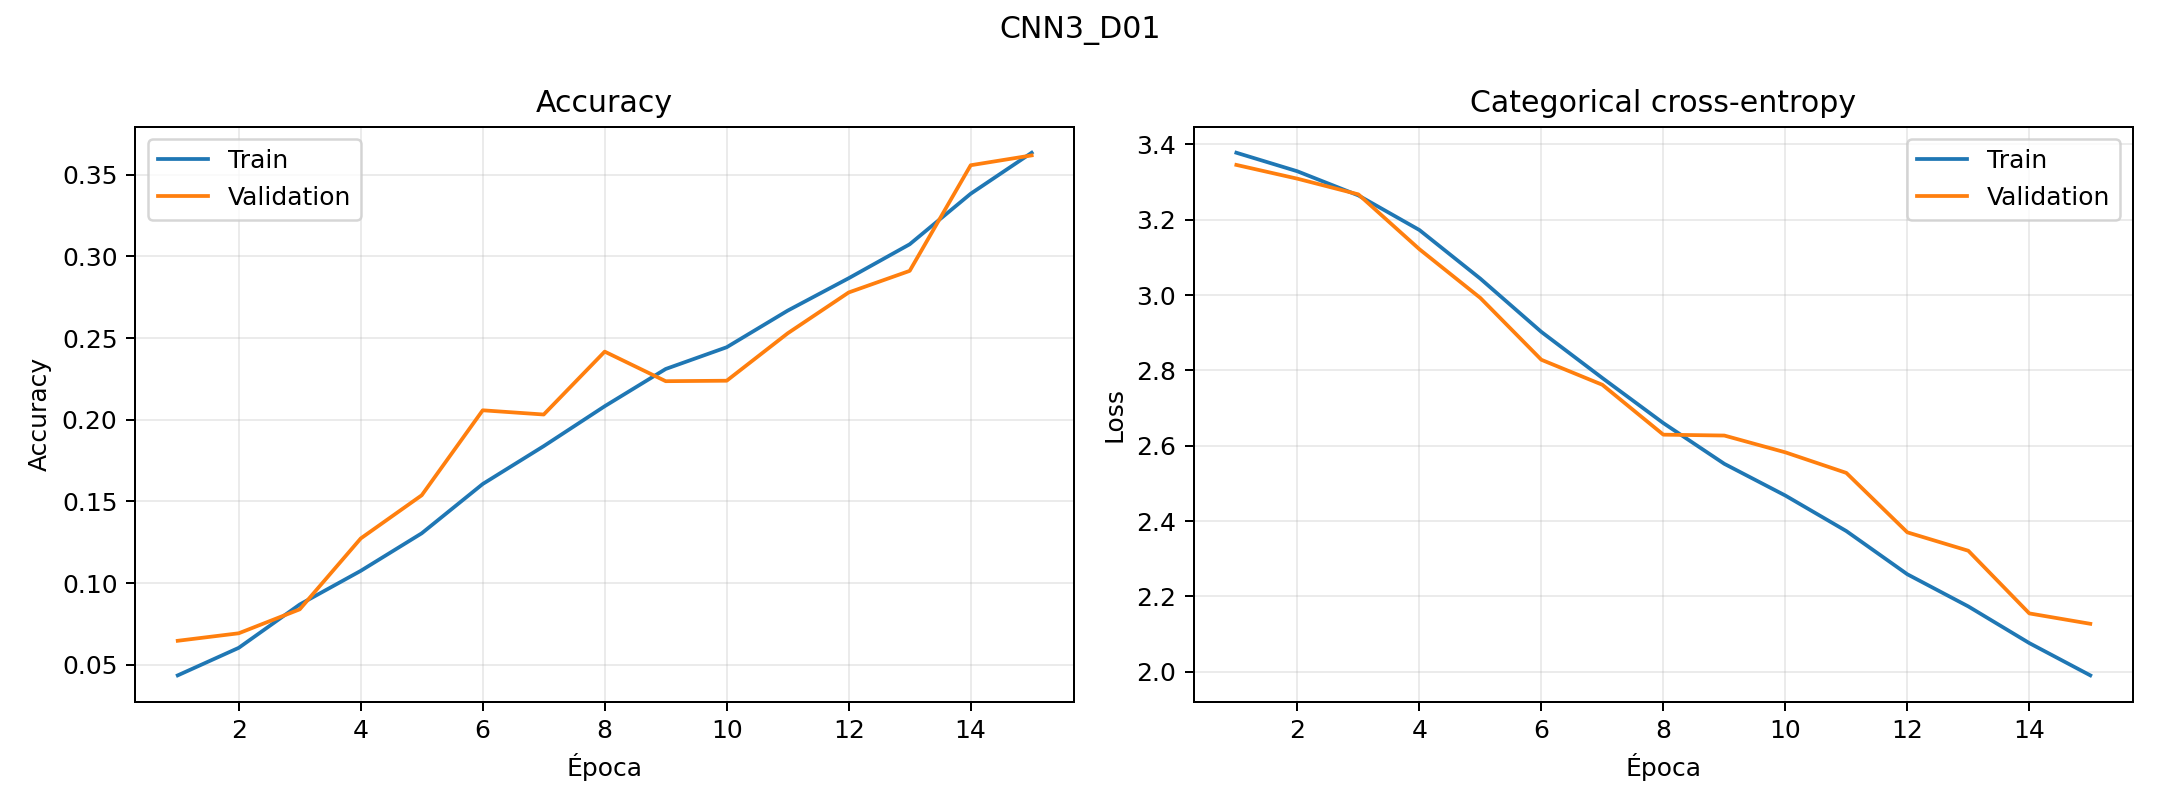

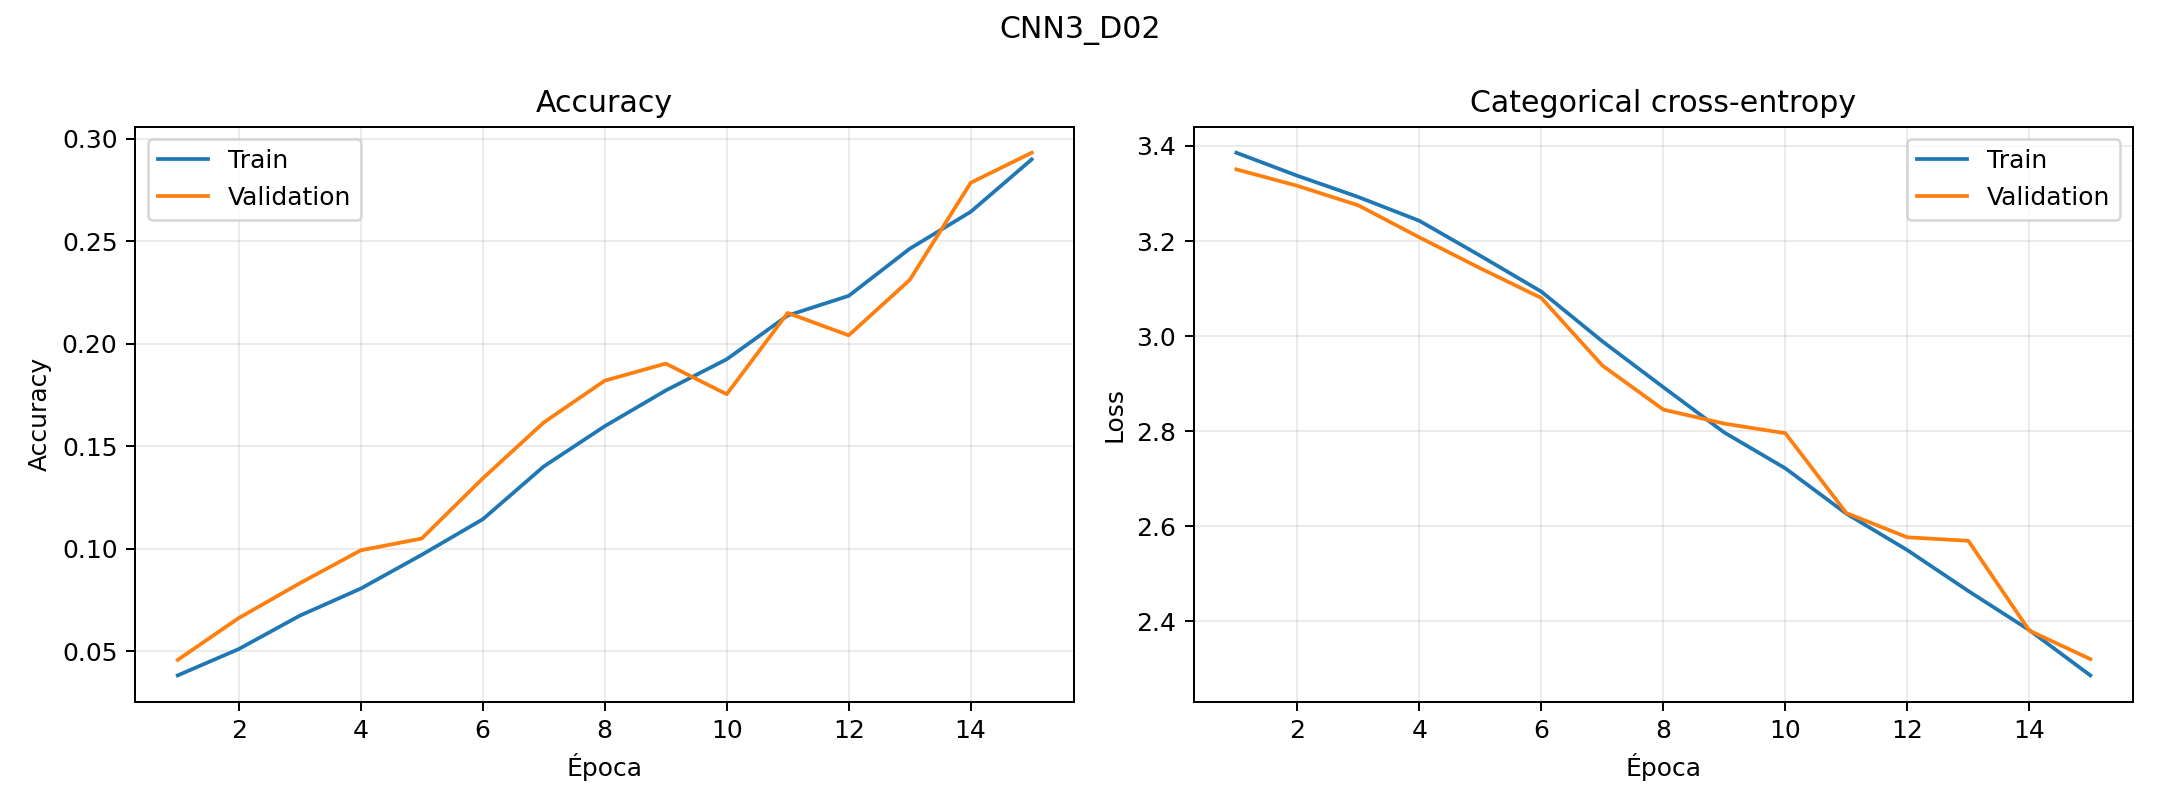

In [9]:
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id in ['CNN3_D01','CNN3_D02']"))
display(IPImage(filename="outputs/figures/history_cnn3_d01.png"))
display(IPImage(filename="outputs/figures/history_cnn3_d02.png"))

La ejecución real alcanzó 37.16% en train y 36.18% en validation (brecha +0.99 puntos porcentuales), con loss de validación 2.1272. Se entrenaron 15 épocas en 269.5 s. Esto muestra una brecha pequeña entre entrenamiento y validación.

La ejecución real alcanzó 29.99% en train y 29.31% en validation (brecha +0.68 puntos porcentuales), con loss de validación 2.3206. Se entrenaron 15 épocas en 283.9 s. Esto muestra una brecha pequeña entre entrenamiento y validación.

Según validation, la mejor tasa de Dropout fue **0.1**.

### 10.1 Experimento controlado de learning rate

Como learning rate 0.001 mostró aprendizaje lento, se repitió Dropout 0.1 con 0.01,
sin cambiar ninguna otra variable. Esto separa el efecto de tasa de aprendizaje del efecto
de Dropout.

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
4,CNN3_D01_LR01,CNN3_D01_LR01,"CNN2 + Dropout(0.1), SGD learning_rate=0.01",0.01,0.1,64.0,15.0,14.0,11.0,False,...,0.230558,0.440887,254.320203,2120413.0,0.864368,0.433982,0.879371,0.864368,0.860896,Test no consultado durante selección; resultad...


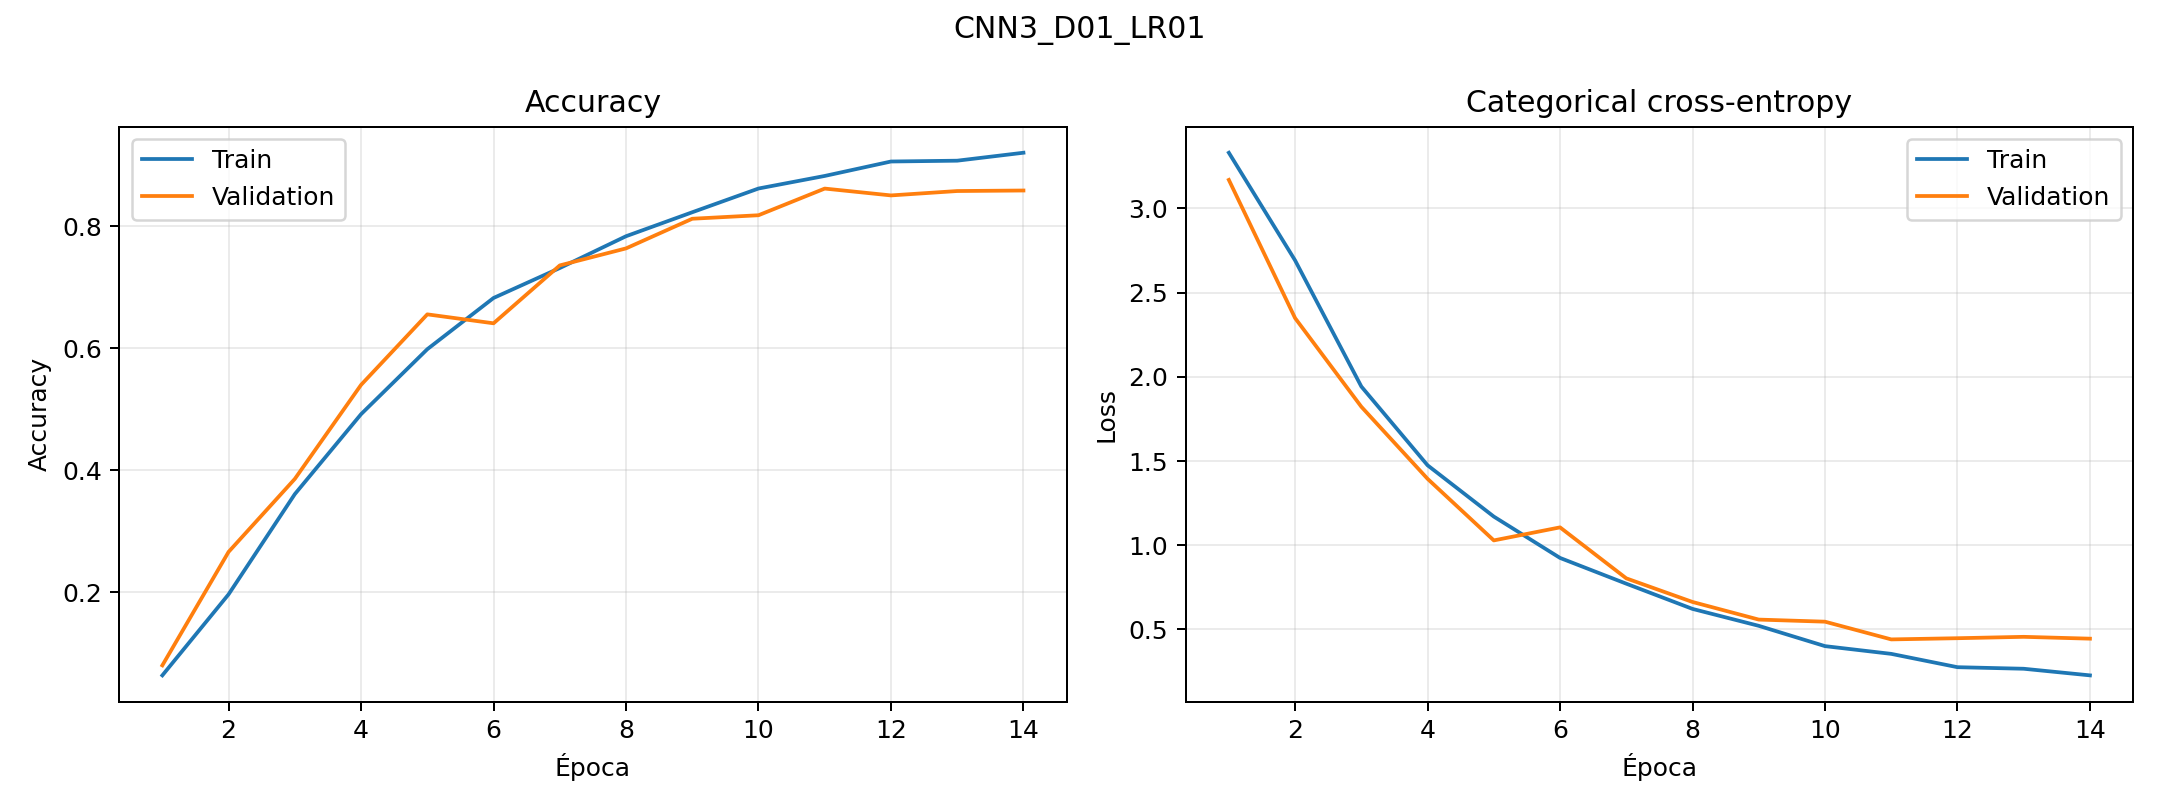

In [10]:
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id == 'CNN3_D01_LR01'"))
display(IPImage(filename="outputs/figures/history_cnn3_d01_lr01.png"))

La ejecución real alcanzó 92.48% en train y 86.15% en validation (brecha +6.33 puntos porcentuales), con loss de validación 0.4409. Se entrenaron 14 épocas en 254.3 s. Esto muestra una brecha apreciable compatible con sobreajuste. El cambio frente a la misma arquitectura con learning rate 0.001 fue +49.97 puntos porcentuales.

## 11. Image Augmentation

La mejor CNN base se reentrenó con desplazamiento horizontal/vertical 0.1, rotación 10°
y zoom 0.1. No se usa flip horizontal: en gatos/perros una reflexión suele conservar la
clase, pero en ASL puede alterar relaciones espaciales relevantes entre mano y dedos.
Validation y test conservan únicamente `rescale`.

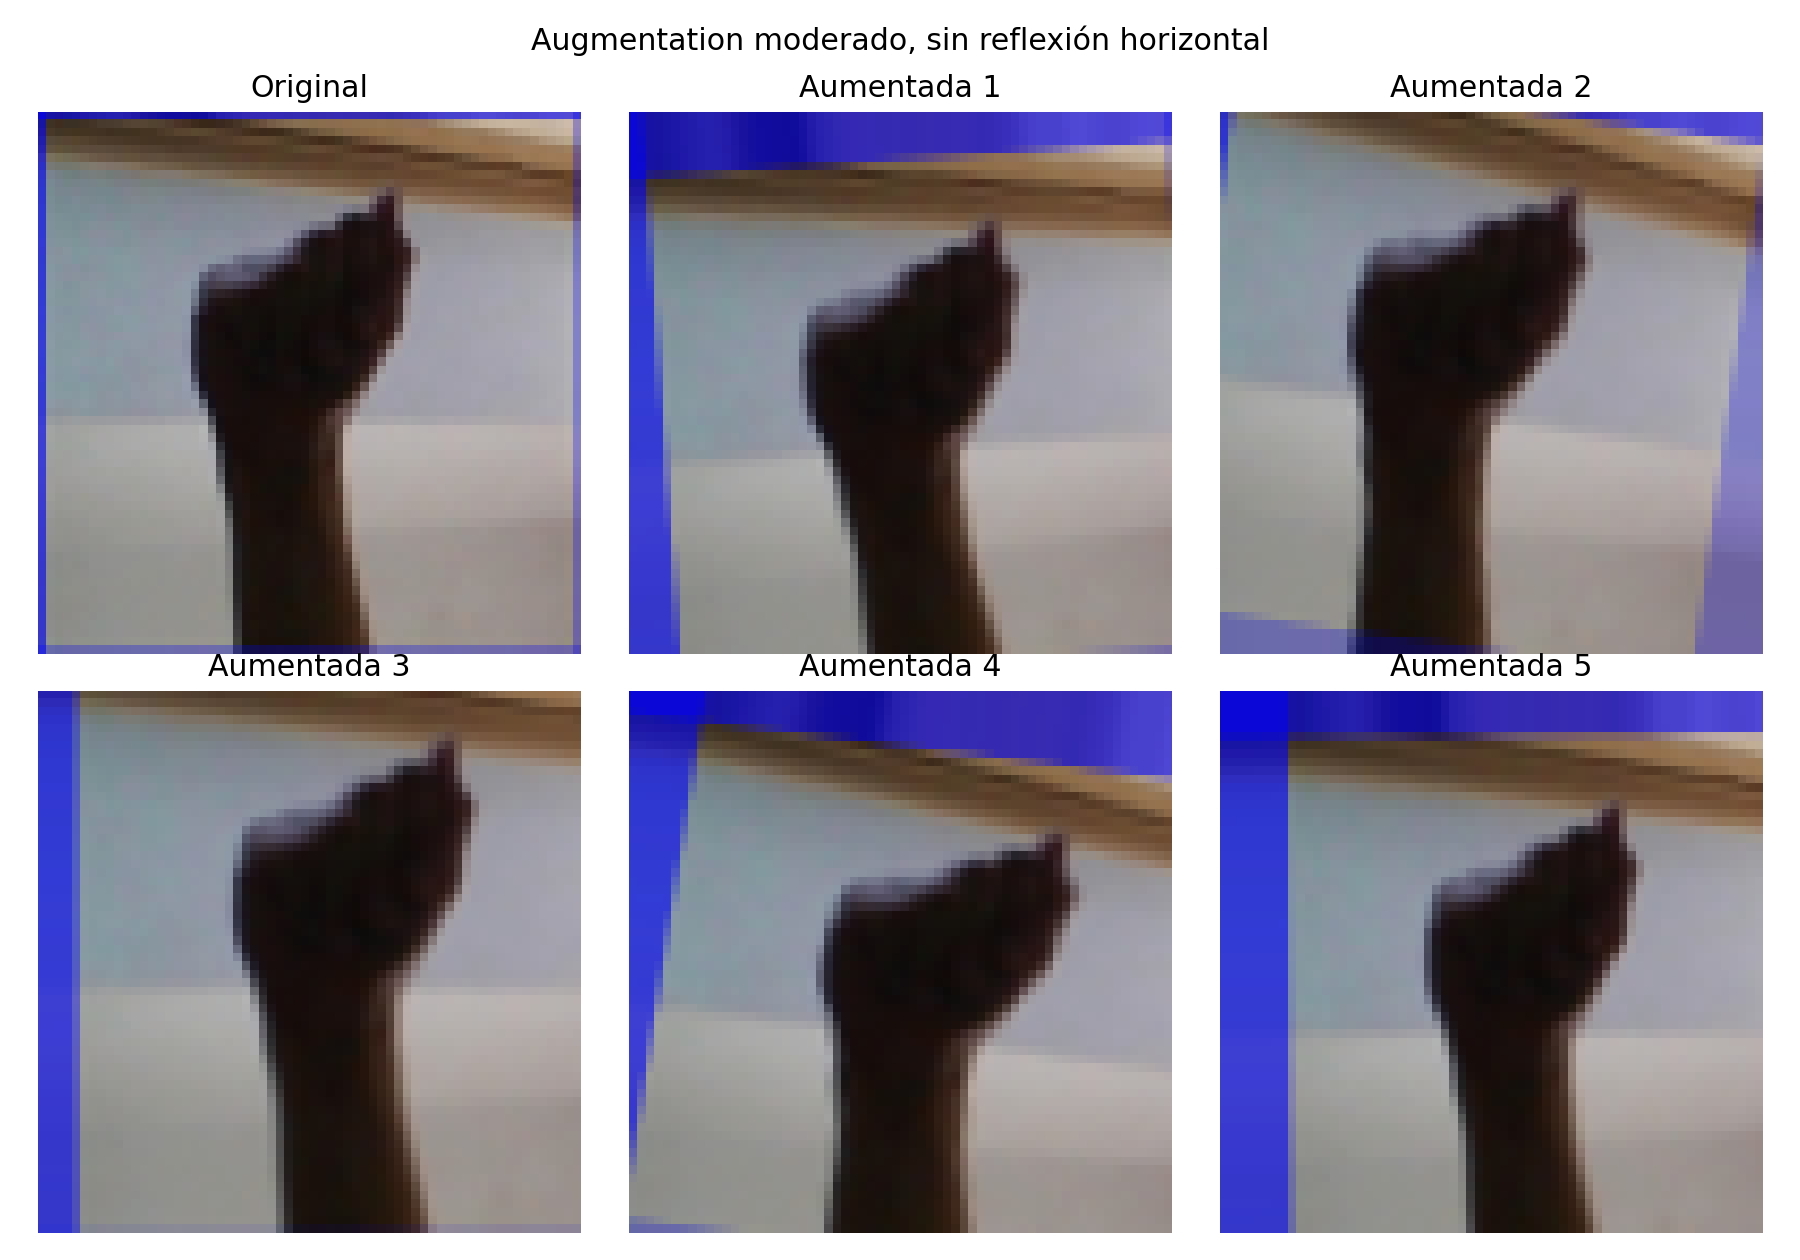

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
7,CNN_AUG,CNN_AUG,"CNN2 + Dropout(0.1), SGD learning_rate=0.01 + ...",0.01,0.1,64.0,15.0,15.0,15.0,True,...,0.499248,0.560798,325.74049,2120413.0,0.809483,0.548041,0.82326,0.809483,0.802733,Test no consultado durante selección; resultad...


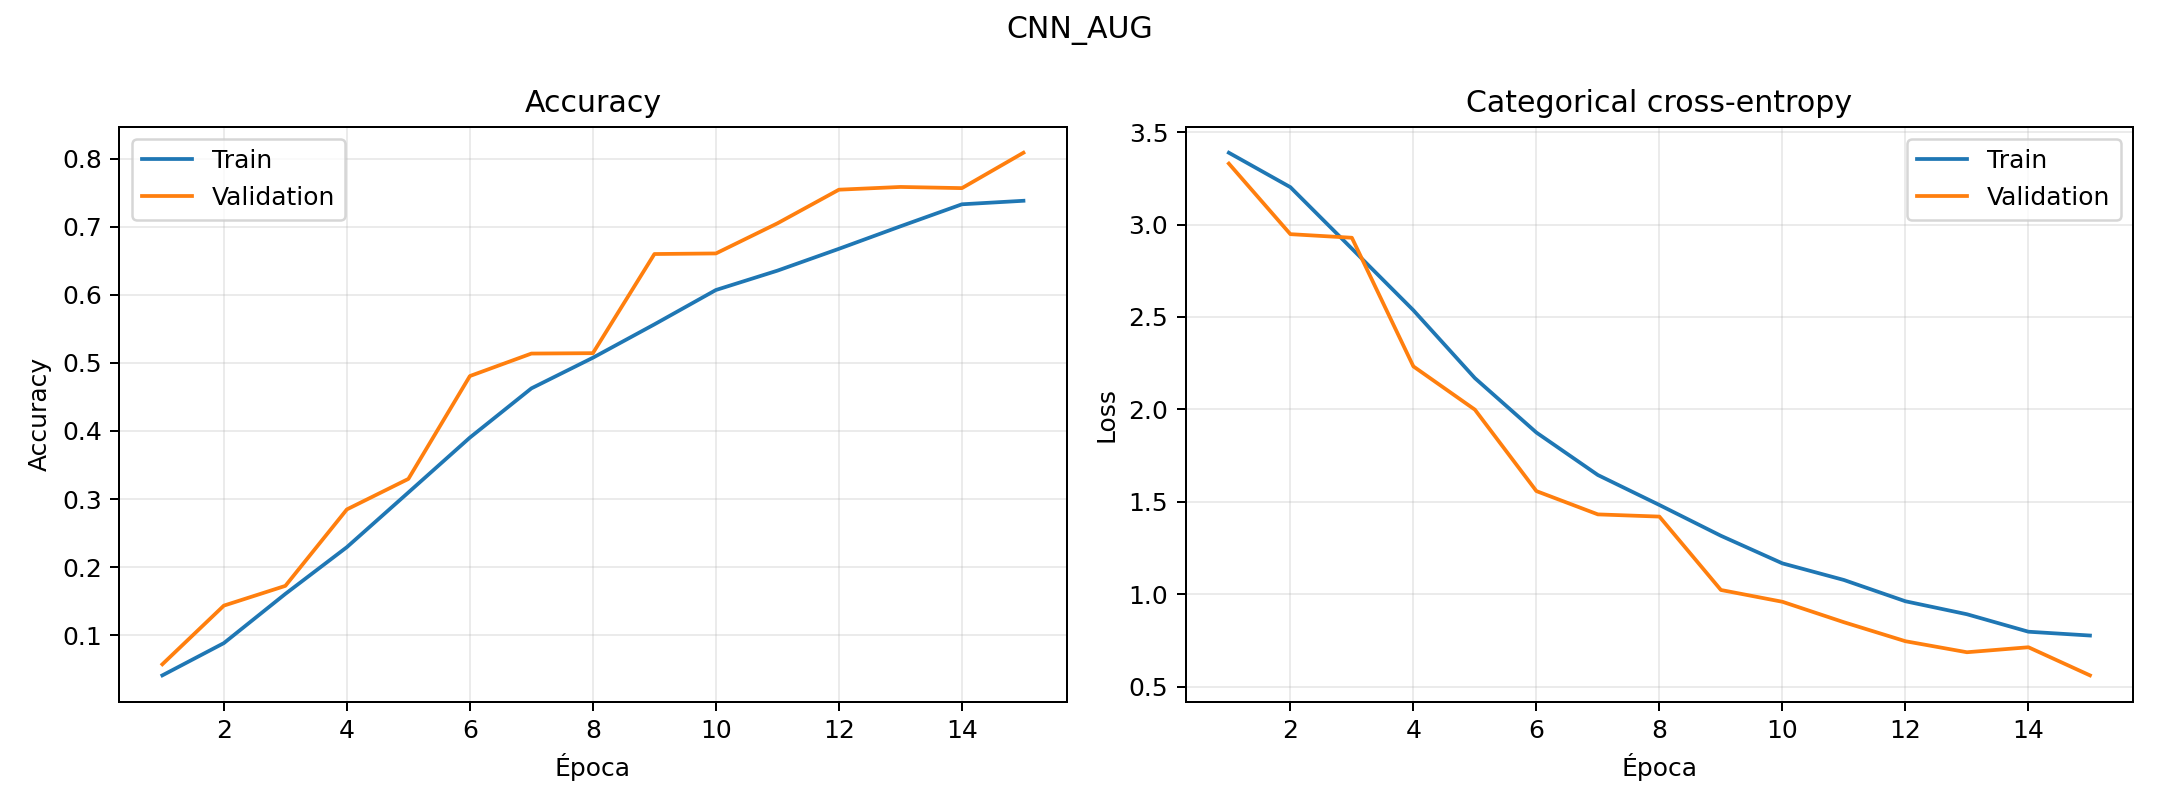

In [11]:
display(IPImage(filename="outputs/figures/augmentation_examples.png"))
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id == 'CNN_AUG'"))
display(IPImage(filename="outputs/figures/history_cnn_aug.png"))

La ejecución real alcanzó 82.86% en train y 80.89% en validation (brecha +1.97 puntos porcentuales), con loss de validación 0.5608. Se entrenaron 15 épocas en 325.7 s. Esto muestra una brecha pequeña entre entrenamiento y validación. La base elegida fue CNN3_D01_LR01 y el cambio de validation accuracy con augmentation fue -5.26 puntos porcentuales.

## 12. Fully Connected

`Flatten` convierte los 64×64×3 píxeles en un vector; Dense(128) aprende sin extracción
espacial por convoluciones. Esto permite medir el valor de Conv2D y muestra el gran número
de parámetros que puede producir una representación completamente conectada.

Model: "fully_connected_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,576,733 (6.01 MB)

 Trainable params: 1,576,733 (6.01 MB)

 Non-trainable params: 0 (0.00 B)

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
5,FC1,FC1,Flatten-Dense(128)-Softmax(29),0.01,0.0,64.0,10.0,10.0,3.0,False,...,3.367314,3.367313,57.870452,1576733.0,0.034483,3.367315,0.001189,0.034483,0.002299,Test no consultado durante selección; resultad...
6,FC2,FC2,Flatten-Dense(256)-Dropout(0.1)-Softmax(29),0.01,0.1,64.0,10.0,10.0,7.0,False,...,2.521947,2.542168,61.328155,3153437.0,0.218678,2.571597,0.284368,0.218678,0.180852,Test no consultado durante selección; resultad...


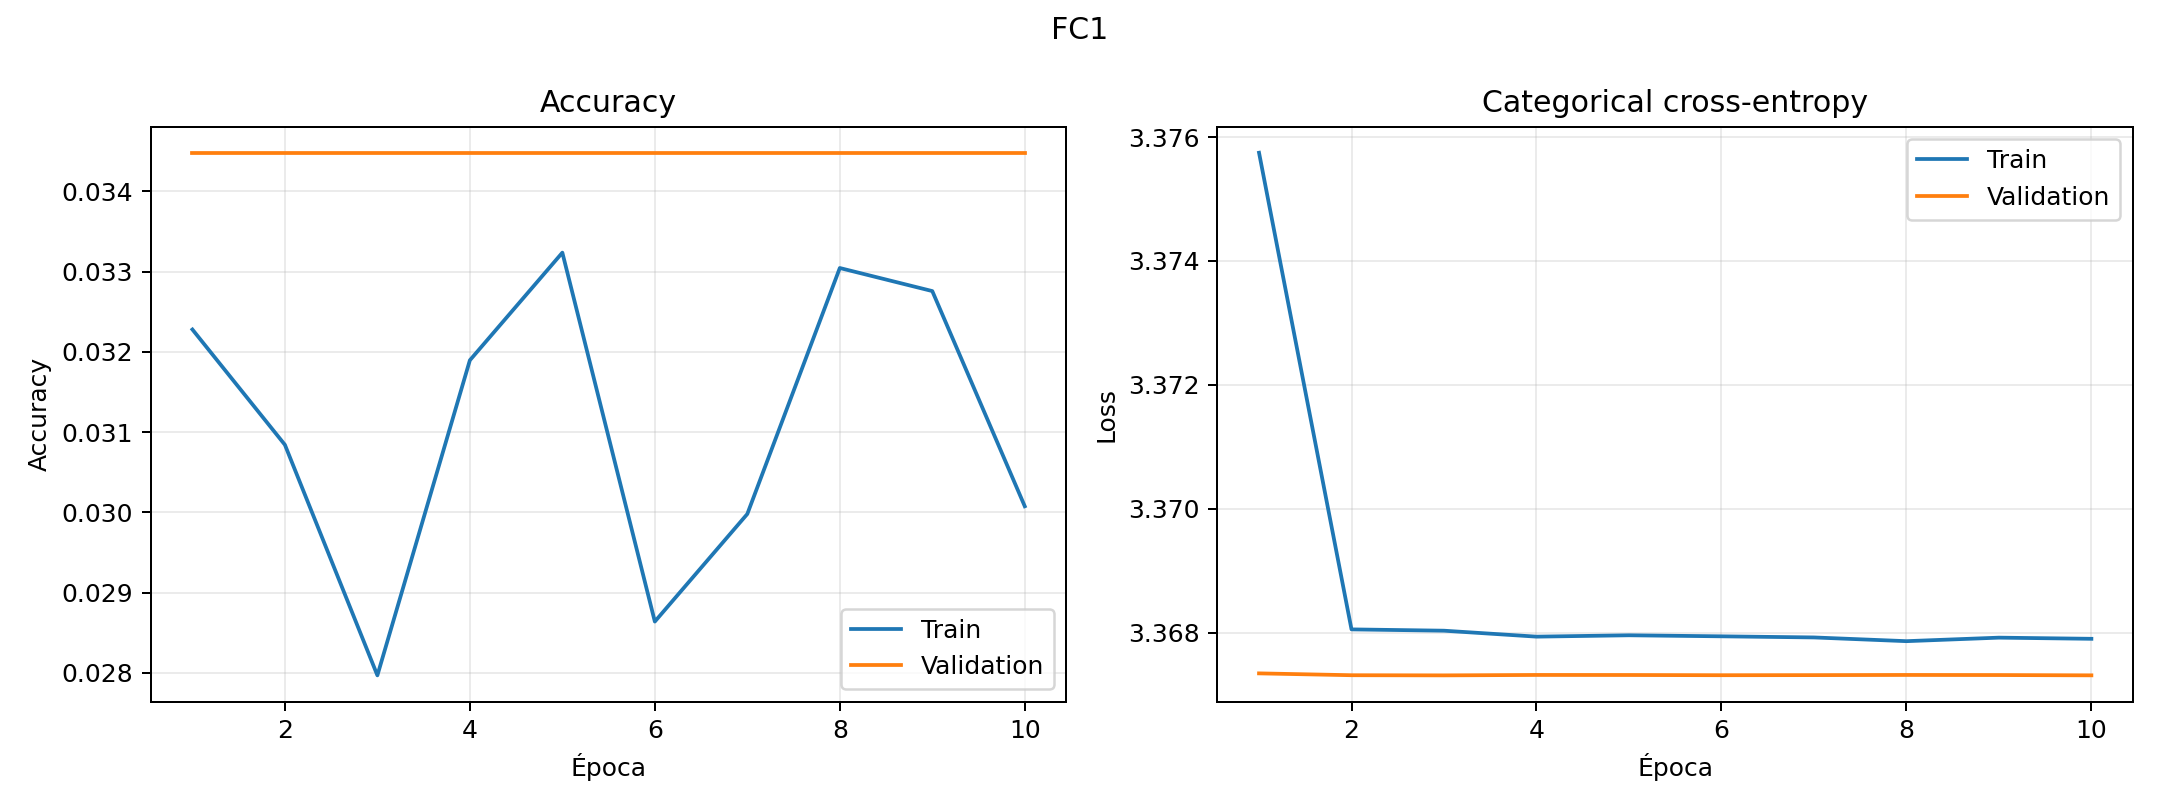

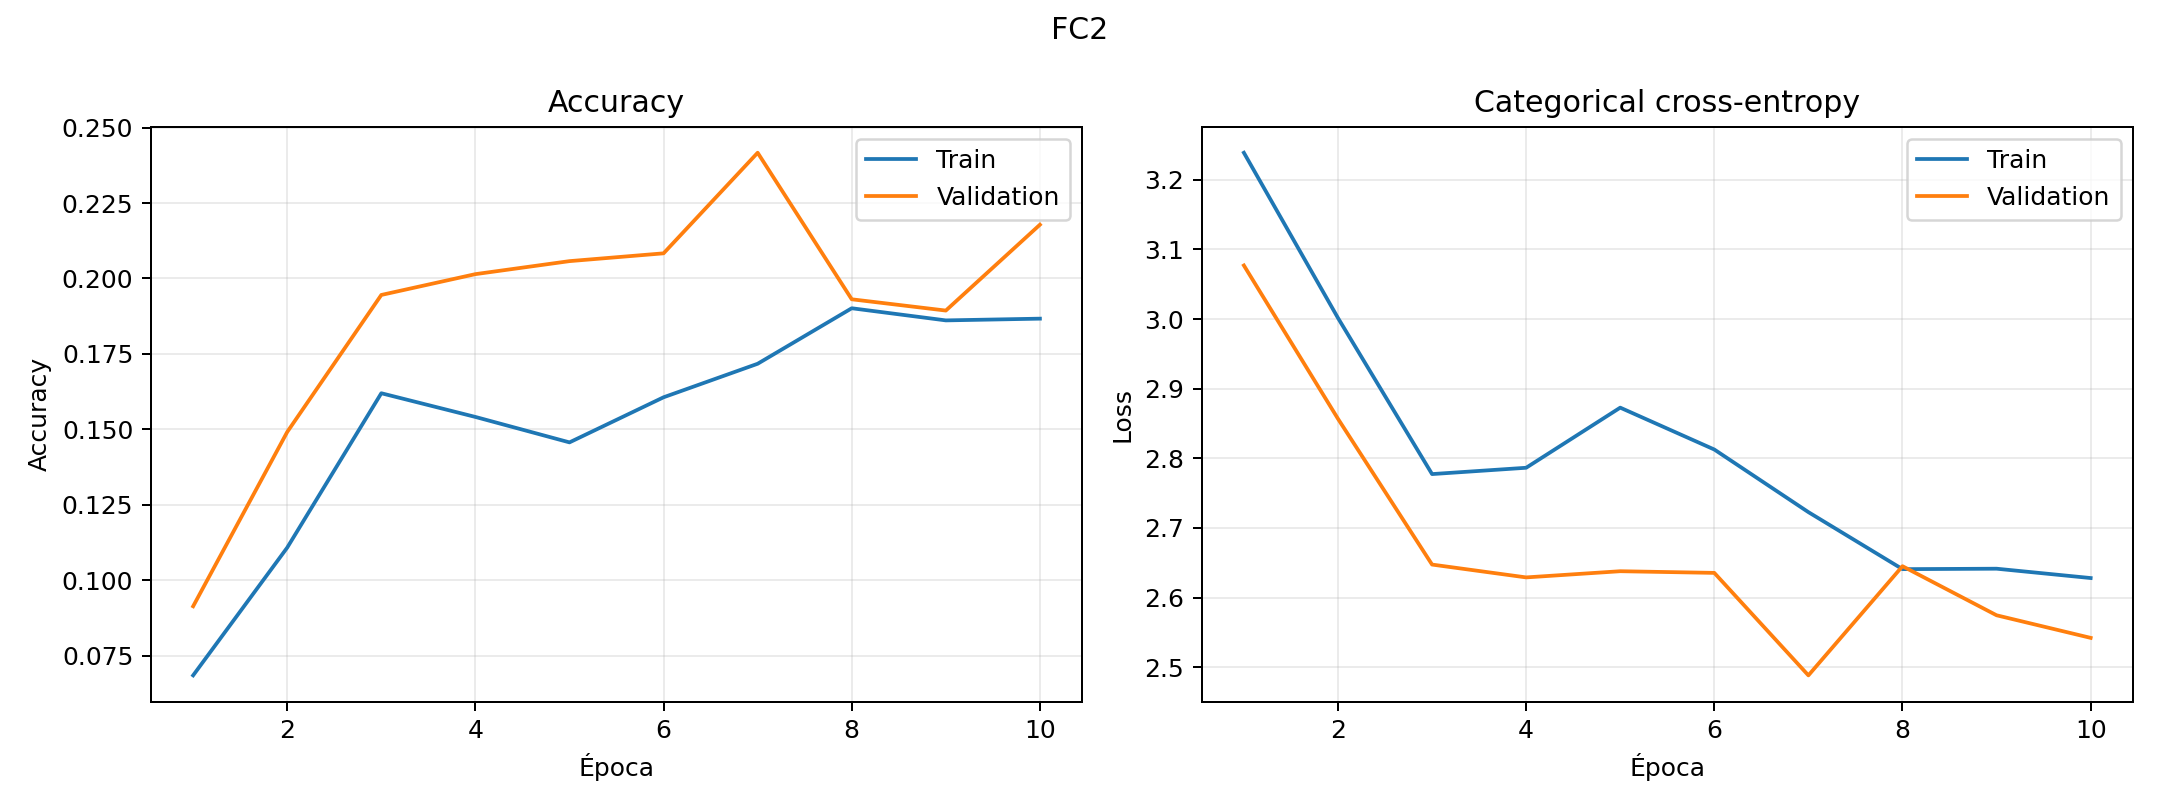

In [12]:
modelo_fc = build_fully_connected(learning_rate=0.01)
modelo_fc.summary()
display(pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id in ['FC1','FC2']"))
display(IPImage(filename="outputs/figures/history_fc1.png"))
display(IPImage(filename="outputs/figures/history_fc2.png"))

La ejecución real alcanzó 3.45% en train y 3.45% en validation (brecha +0.00 puntos porcentuales), con loss de validación 3.3673. Se entrenaron 10 épocas en 57.9 s. Esto muestra una brecha pequeña entre entrenamiento y validación.

La ejecución real alcanzó 22.37% en train y 21.78% en validation (brecha +0.58 puntos porcentuales), con loss de validación 2.5422. Se entrenaron 10 épocas en 61.3 s. Esto muestra una brecha pequeña entre entrenamiento y validación. La variación Dense(256)+Dropout(0.1) cambió validation en +18.33 puntos porcentuales.

## 13. SVM

SVM es una referencia clásica adecuada para fronteras de decisión de alto margen. Cada imagen
64×64×3 se aplana; `StandardScaler` y PCA(100) se ajustan **solo con TRAIN** y después se
aplican sin refit a validation/test. Se comparan kernel lineal y RBF con C=1, sin una búsqueda
masiva de hiperparámetros.

In [13]:
svm_rows = pd.read_csv("outputs/metrics/experiments.csv").query("experiment_id.str.startswith('SVM')", engine="python")
display(svm_rows)

,experiment_id,model_name,architecture,learning_rate,dropout,batch_size,epochs_requested,epochs_trained,best_epoch,augmentation,...,train_loss,validation_loss,training_time,parameters,test_accuracy,test_loss,macro_precision,macro_recall,macro_f1,notes
8,SVM_LINEAR,SVM LINEAR,"Flatten-StandardScaler-PCA-SVC(kernel=linear,C=1)",NaN,NaN,NaN,NaN,NaN,NaN,False,...,NaN,NaN,7.321281,NaN,0.749138,NaN,0.752754,0.749138,0.748624,StandardScaler y PCA(100) ajustados solo con T...
9,SVM_RBF,SVM RBF,"Flatten-StandardScaler-PCA-SVC(kernel=rbf,C=1)",NaN,NaN,NaN,NaN,NaN,NaN,False,...,NaN,NaN,6.217814,NaN,0.798563,NaN,0.802642,0.798563,0.797940,StandardScaler y PCA(100) ajustados solo con T...


SVM lineal obtuvo 75.98% en validation y
74.91% en test; SVM RBF obtuvo
80.72% y
79.86%, respectivamente. El kernel seleccionado
por validation fue **SVM_RBF**.